# Diabetes Prediction: Logistic Regression Base Model

**ICS 3202 | CAT 2 | Felicia Agwata, Joy Karanja, and Audrey Ayieko**

**Question:** Can a machine learning model accurately predict whether a patient has diabetes based on clinical and demographic indicators?

| Order | Presenter - Part |
| :--- | :--- |
| 1 | Felicia Agwata - Data Cleaning & Base Model Setup |
| 2 | Joy Karanja - EDA & Validation Expert |
| 3 | Audrey Ayieko - Comparative Model & Repository Lead |

## 1.  Data Cleaning & Base Model Setup

### 1.1 Our Approach
We use **supervised binary classification** to predict whether a patient has diabetes (`1`) or does not have diabetes (`0`). The selected base model is **Logistic Regression**, which serves as an interpretable baseline for medical tabular data.

### 1.2 Loading and Inspecting the Dataset
We load the raw diabetes prediction dataset into a Pandas DataFrame to inspect its structure. The dataset contains 9 columns covering patient health indicators (such as BMI, HbA1c level, blood glucose level, hypertension, and heart disease) and the target variable (`diabetes`).

In [ ]:
import pandas as pd

df = pd.read_csv('diabetes_prediction_dataset.csv')
display(df.head())

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


### 1.3 Initial Dataset Inspection
Before performing any cleaning, we check the overall structure, dimensions, and data types of our dataset. As shown below, the raw dataset contains **100,000 records and 9 features**, consisting of a mix of categorical text columns (`object`) and numerical indicators (`float64`, `int64`).

In [ ]:
# Check dataset shape and data types
print("Dataset Shape:", df.shape)
print("\nData Types:")
print(df.dtypes)

# Preview the first few rows
display(df.head())

Dataset Shape: (100000, 9)

Data Types:
gender                  object
age                    float64
hypertension             int64
heart_disease            int64
smoking_history         object
bmi                    float64
HbA1c_level            float64
blood_glucose_level      int64
diabetes                 int64
dtype: object


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


### 1.4 Handling Duplicate Records
To prevent model bias caused by redundant entries, we check for duplicate rows. Our script identified and removed **3,854 duplicate rows**, refining our active dataset size from 100,000 down to **96,146 clean records**.

In [ ]:
# Check for duplicate rows
print(f"Duplicate rows before cleaning: {df.duplicated().sum()}")

# Drop duplicates and reset index
df = df.drop_duplicates().reset_index(drop=True)

print(f"Dataset shape after dropping duplicates: {df.shape}")

Duplicate rows before cleaning: 3854
Dataset shape after dropping duplicates: (96146, 9)


### 1.5 Missing Value Verification
We inspect every column for null or missing values. As shown in the output below, there are **0 missing values** across all features, confirming that our dataset is complete.

In [ ]:
# Check missing values explicitly per column
print("Missing values per column:")
print(df.isnull().sum())

Missing values per column:
gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64


### 1.6 Categorical Variable Encoding
Since machine learning algorithms require numerical data to perform calculations, we use `LabelEncoder` to transform text-based categorical columns—specifically `gender` and `smoking_history`—into numerical values (`df_cleaned`).

In [ ]:
from sklearn.preprocessing import LabelEncoder

# Create a copy for cleaning/encoding
df_cleaned = df.copy()
label_encoder = LabelEncoder()

# Apply label encoding to categorical columns
categorical_cols = ['gender', 'smoking_history']
for col in categorical_cols:
    df_cleaned[col] = label_encoder.fit_transform(df_cleaned[col])

print("Cleaned and Encoded DataFrame Preview:")
display(df_cleaned.head())

Cleaned and Encoded DataFrame Preview:


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,0,80.0,0,1,4,25.19,6.6,140,0
1,0,54.0,0,0,0,27.32,6.6,80,0
2,1,28.0,0,0,4,27.32,5.7,158,0
3,0,36.0,0,0,1,23.45,5.0,155,0
4,1,76.0,1,1,1,20.14,4.8,155,0


# Data Loading, Exploration, and Predictive Modeling
This section covers importing the diabetes prediction dataset, performing initial cleaning, exploring the data visually, and training a baseline Random Forest model with cross-validation.

In [4]:
from google.colab import files
uploaded = files.upload()

Saving diabetes_prediction_dataset.csv to diabetes_prediction_dataset.csv


### 1. Data Loading and Cleaning
We load the uploaded CSV file into a Pandas DataFrame, check for missing values, and clean any duplicate records to ensure data integrity.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the dataset
df = pd.read_csv('diabetes_prediction_dataset.csv')

# 2. Quick check for missing values or duplicates
print("Missing values:", df.isnull().sum().sum())
df = df.drop_duplicates()
print("Dataset size after cleaning:", df.shape)

Missing values: 0
Dataset size after cleaning: (96146, 9)


### 2. Exploratory Data Analysis (EDA)
We generate visualizations to inspect the distribution of blood glucose levels and examine the relationship between BMI and diabetes status.

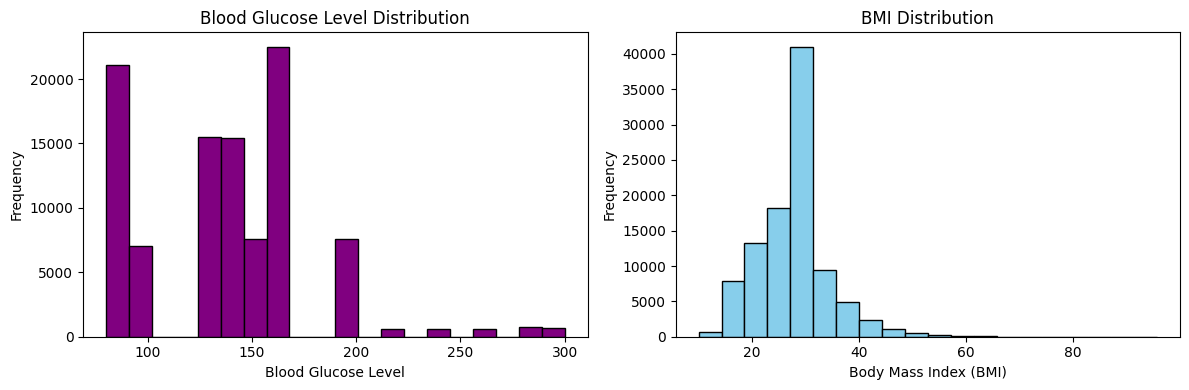

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv('diabetes_prediction_dataset.csv')

# Set up the figure for side-by-side charts
plt.figure(figsize=(12, 4))

# Chart 1: Blood Glucose Level Distribution
plt.subplot(1, 2, 1)
df['blood_glucose_level'].plot(kind='hist', bins=20, color='purple', edgecolor='black')
plt.title('Blood Glucose Level Distribution')
plt.xlabel('Blood Glucose Level')
plt.ylabel('Frequency')

# Chart 2: BMI Distribution
plt.subplot(1, 2, 2)
df['bmi'].plot(kind='hist', bins=20, color='skyblue', edgecolor='black')
plt.title('BMI Distribution')
plt.xlabel('Body Mass Index (BMI)')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

### 3. Predictive Modeling (Random Forest)
We prepare the features and target variable, encode categorical text columns, and evaluate a baseline Random Forest classifier using 5-Fold Cross-Validation.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

# Prepare our inputs (X) and target answer (y)
# We convert text columns like gender into numbers automatically
X = pd.get_dummies(df.drop(columns=['diabetes']), drop_first=True)
y = df['diabetes']

# Set up our base model
model = RandomForestClassifier(random_state=42)

# Test the model using 5-Fold Cross Validation
scores = cross_val_score(model, X, y, cv=5)

print("Accuracy scores for each test round:", scores)
print("Average Accuracy:", scores.mean())

Accuracy scores for each test round: [0.96900676 0.96947319 0.96656092 0.96910916 0.96905715]
Average Accuracy: 0.9686414373419285


## Task 4: Comparing Different Machine Learning Models

In this section, we compare the Random Forest model with Logistic Regression and Support Vector Machine (SVM). We use five-fold stratified cross-validation to evaluate the models using accuracy, precision, recall, F1-score and ROC-AUC.

In [ ]:
# Task 4: Comparing different machine learning models

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import pandas as pd

# Define the cross-validation method
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Create the models we want to compare
models = {
    "Random Forest": RandomForestClassifier(random_state=42),

    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, class_weight="balanced")
    ),

    "SVM": make_pipeline(
        StandardScaler(),
        LinearSVC(class_weight="balanced", random_state=42)
    )
}

# Choose the measures to evaluate the models
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

# Store the results
results = []

# Test each model using the same cross-validation method
for name, model in models.items():

    print("Testing", name)

    scores = cross_validate(
        model,
        X,
        y,
        cv=cv,
        scoring=scoring
    )

    results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1 Score": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean()
    })

# Display the final comparison
results_df = pd.DataFrame(results)

display(results_df.round(4))

Testing Random Forest
Testing Logistic Regression
Testing SVM


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Random Forest,0.9686,0.9454,0.6832,0.7932,0.9611
1,Logistic Regression,0.8863,0.4298,0.8808,0.5777,0.9619
2,SVM,0.8869,0.4312,0.8819,0.5791,0.9619


### Interpretation of Model Comparison Results

The three models were evaluated using five-fold stratified cross-validation. Random Forest achieved the highest accuracy of 96.86%, precision of 94.54% and F1-score of 79.32%. This shows that it provided the best balance between correctly identifying diabetes-positive cases and avoiding false-positive predictions.

Logistic Regression achieved a recall of 88.08%, while SVM achieved 88.19%. These models identified a higher proportion of positive cases than Random Forest, but their precision and F1-scores were lower. Both models also achieved a ROC-AUC of 0.9619, slightly higher than the Random Forest score of 0.9611.

Overall, Random Forest performed best based on accuracy, precision and F1-score, while SVM achieved the highest recall. The results show that different algorithms have different strengths. Further testing would be necessary before selecting a model for real clinical use.